In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import IPython

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer

In [2]:
train_test_split?

Signature:
train_test_split(
    *arrays,
    test_size=None,
    train_size=None,
    random_state=None,
    shuffle=True,
    stratify=None,
)
Docstring:
Split arrays or matrices into random train and test subsets.

Quick utility that wraps input validation,
``next(ShuffleSplit().split(X, y))``, and application to input data
into a single call for splitting (and optionally subsampling) data into a
one-liner.

Read more in the :ref:`User Guide <cross_validation>`.

Parameters
----------
*arrays : sequence of array-like of shape (n_samples,) or             (n_samples, n_outputs)
    Indexable data-structures can be arrays, lists, dataframes, scipy
    sparse matrices or pandas dataframes with consistent first dimension.

test_size : float or int, default=None
    If float, should be between 0.0 and 1.0 and represent the proportion
    of the dataset to include in the test split. If int, represents the
    absolute number of test samples. If None, the value is set to the
    complement 

In [3]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv'

In [4]:
!wget $data -O data-week-3.csv

--2026-11-11 10:22:33--  https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.111.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 977501 (955K) [text/plain]
Saving to: ‘data-week-3.csv’

data-week-3.csv     100%[===================>] 954.59K  --.-KB/s    in 0.009s  

2026-11-11 10:22:33 (106 MB/s) - ‘data-week-3.csv’ saved [977501/977501]



In [5]:
df = pd.read_csv('data-week-3.csv')

In [6]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [7]:
df.columns =df.columns.str.lower().str.replace(' ','_')

In [8]:
categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)

In [9]:
categorical_columns

['customerid',
 'gender',
 'partner',
 'dependents',
 'phoneservice',
 'multiplelines',
 'internetservice',
 'onlinesecurity',
 'onlinebackup',
 'deviceprotection',
 'techsupport',
 'streamingtv',
 'streamingmovies',
 'contract',
 'paperlessbilling',
 'paymentmethod',
 'totalcharges',
 'churn']

In [10]:
for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ' ,'_')

In [11]:
df.totalcharges

0         29.85
1        1889.5
2        108.15
3       1840.75
4        151.65
         ...   
7038     1990.5
7039     7362.9
7040     346.45
7041      306.6
7042     6844.5
Name: totalcharges, Length: 7043, dtype: str

In [12]:
df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')

In [13]:
df.totalcharges = df.totalcharges.fillna(0)

In [14]:
df.churn = (df.churn =='yes').astype(int)

In [15]:
df_full_train , df_test = train_test_split(df,test_size=0.2,random_state=1)

In [16]:
len(df_full_train) , len (df_test)

(5634, 1409)

In [17]:
df_train , df_val = train_test_split(df_full_train,test_size=0.25,random_state=1)

In [18]:
len(df_train) , len (df_val) , len(df_test)

(4225, 1409, 1409)

In [19]:
df_train = df_train.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)

In [20]:
y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

In [21]:
del df_train['churn']
del df_val['churn']
del df_test['churn']

In [22]:
numerical = ['tenure','monthlycharges','totalcharges']

In [23]:
categorical = [ 'gender', 'seniorcitizen', 'partner', 'dependents',
        'phoneservice', 'multiplelines', 'internetservice',
       'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
       'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
       'paymentmethod']

In [24]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

model = LogisticRegression(solver='lbfgs', max_iter=5000)
model.fit(X_train,y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [25]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[: ,1]
churn_decision = (y_pred >= 0.5)
(y_val == churn_decision).mean()

np.float64(0.8034066713981547)

In [26]:
dv.get_feature_names_out()

array(['contract=month-to-month', 'contract=one_year',
       'contract=two_year', 'dependents=no', 'dependents=yes',
       'deviceprotection=no', 'deviceprotection=no_internet_service',
       'deviceprotection=yes', 'gender=female', 'gender=male',
       'internetservice=dsl', 'internetservice=fiber_optic',
       'internetservice=no', 'monthlycharges', 'multiplelines=no',
       'multiplelines=no_phone_service', 'multiplelines=yes',
       'onlinebackup=no', 'onlinebackup=no_internet_service',
       'onlinebackup=yes', 'onlinesecurity=no',
       'onlinesecurity=no_internet_service', 'onlinesecurity=yes',
       'paperlessbilling=no', 'paperlessbilling=yes', 'partner=no',
       'partner=yes', 'paymentmethod=bank_transfer_(automatic)',
       'paymentmethod=credit_card_(automatic)',
       'paymentmethod=electronic_check', 'paymentmethod=mailed_check',
       'phoneservice=no', 'phoneservice=yes', 'seniorcitizen',
       'streamingmovies=no', 'streamingmovies=no_internet_service',

In [27]:
X_val

array([[0.0000e+00, 0.0000e+00, 1.0000e+00, ..., 1.0000e+00, 7.1000e+01,
        4.9734e+03],
       [1.0000e+00, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        2.0750e+01],
       [1.0000e+00, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        2.0350e+01],
       ...,
       [1.0000e+00, 0.0000e+00, 0.0000e+00, ..., 1.0000e+00, 1.8000e+01,
        1.0581e+03],
       [1.0000e+00, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        9.3300e+01],
       [1.0000e+00, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 3.0000e+00,
        2.9285e+02]], shape=(1409, 45))

In [28]:
## 4.2 Accuracy and dummy model
### Evaluate the model on different thresholds

In [29]:
len(y_val)

1409

In [30]:
(y_val == churn_decision).sum()

np.int64(1132)

In [31]:
thresholds = np.linspace(0,1,21)
thresholds

array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
       0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  ])

In [32]:
scores = []

for t in thresholds:
    churn_decision = ( y_pred >= t)
    score = (y_val == churn_decision).mean()
    print('%.2f , %.3f' % (t,score))
    scores.append(score)

0.00 , 0.274
0.05 , 0.513
0.10 , 0.608
0.15 , 0.662
0.20 , 0.703
0.25 , 0.735
0.30 , 0.759
0.35 , 0.764
0.40 , 0.781
0.45 , 0.791
0.50 , 0.803
0.55 , 0.802
0.60 , 0.796
0.65 , 0.789
0.70 , 0.766
0.75 , 0.742
0.80 , 0.729
0.85 , 0.726
0.90 , 0.726
0.95 , 0.726
1.00 , 0.726


In [33]:
scores

[np.float64(0.2739531582682754),
 np.float64(0.5131298793470547),
 np.float64(0.6082327892122072),
 np.float64(0.6621717530163236),
 np.float64(0.7026259758694109),
 np.float64(0.7345635202271115),
 np.float64(0.758694109297374),
 np.float64(0.7643718949609652),
 np.float64(0.7814052519517388),
 np.float64(0.7913413768630234),
 np.float64(0.8034066713981547),
 np.float64(0.8019872249822569),
 np.float64(0.7955997161107168),
 np.float64(0.7885024840312278),
 np.float64(0.765791341376863),
 np.float64(0.7423704755145494),
 np.float64(0.7288857345635202),
 np.float64(0.7260468417317246),
 np.float64(0.7260468417317246),
 np.float64(0.7260468417317246),
 np.float64(0.7260468417317246)]

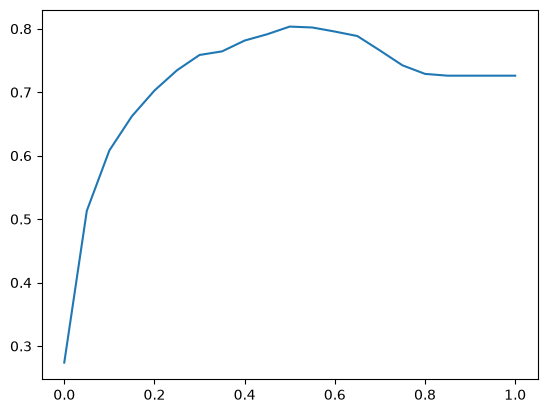

In [34]:
plt.plot(thresholds, scores)

In [35]:
from sklearn.metrics import accuracy_score

In [36]:
accuracy_score(y_val,y_pred >= 0.5)

0.8034066713981547

In [37]:
scores = []

for t in thresholds:
    score = accuracy_score(y_val,y_pred >= t)
    print('%.2f , %.3f' % (t,score))
    scores.append(score)

0.00 , 0.274
0.05 , 0.513
0.10 , 0.608
0.15 , 0.662
0.20 , 0.703
0.25 , 0.735
0.30 , 0.759
0.35 , 0.764
0.40 , 0.781
0.45 , 0.791
0.50 , 0.803
0.55 , 0.802
0.60 , 0.796
0.65 , 0.789
0.70 , 0.766
0.75 , 0.742
0.80 , 0.729
0.85 , 0.726
0.90 , 0.726
0.95 , 0.726
1.00 , 0.726


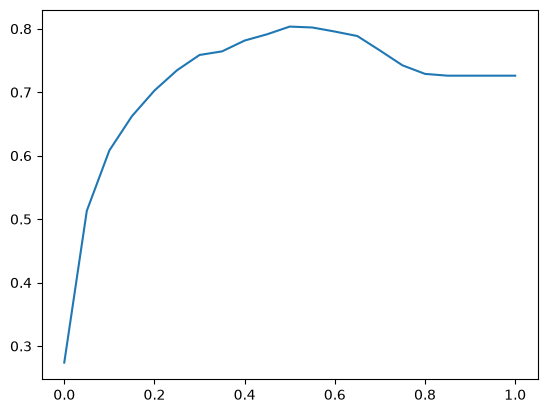

In [38]:
plt.plot(thresholds, scores)

In [39]:
## 4.3 confusion table
### different type of errors and correct decisons
### Arranging them in a table

In [40]:
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

In [41]:
actual_positive

array([False, False, False, ..., False,  True,  True], shape=(1409,))

In [42]:
actual_negative

array([ True,  True,  True, ...,  True, False, False], shape=(1409,))

In [43]:
t = 0.5
preduct_positive = ( y_pred >= t)
preduct_negative = ( y_pred < t)

In [44]:
preduct_positive

array([False, False, False, ..., False,  True,  True], shape=(1409,))

In [45]:
preduct_negative

array([ True,  True,  True, ...,  True, False, False], shape=(1409,))

In [46]:
preduct_positive & actual_positive

array([False, False, False, ..., False,  True,  True], shape=(1409,))

In [47]:
tp = (preduct_positive & actual_positive).sum()

In [48]:
tn = (preduct_negative & actual_negative).sum()

In [49]:
tp

np.int64(212)

In [50]:
tn

np.int64(920)

In [51]:
fp = (preduct_positive & actual_negative).sum()
fn = (preduct_negative & actual_positive).sum()

In [52]:
fp

np.int64(103)

In [53]:
fn

np.int64(174)

In [54]:
confusion_matrix = np.array([
    [tn, fp],
    [fn,tp]
])
confusion_matrix

array([[920, 103],
       [174, 212]])

In [55]:
confusion_matrix / confusion_matrix.sum().round(2)

array([[0.65294535, 0.07310149],
       [0.12349184, 0.15046132]])

In [56]:
## 4.4 Precision and Recall

In [57]:
(tp + tn ) / ( tp + tn + fp + fn )

np.float64(0.8034066713981547)

In [58]:
 p = tp / ( tp + fp )

In [59]:
p

np.float64(0.6730158730158731)

In [60]:
r = tp / ( tp + fn )

In [61]:
r

np.float64(0.5492227979274611)

In [62]:
## 4.5 ROC curves ( Received Operating Characteristics )
### TPR and FRP

In [63]:
tpr = tp / ( tp + fn )

In [64]:
tpr

np.float64(0.5492227979274611)

In [65]:
fpr = fp / ( fp + tn )

In [66]:
fpr

np.float64(0.10068426197458455)

In [67]:
thresholds = np.linspace ( 0 , 1, 101)

In [68]:
thresholds

array([0.  , 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1 ,
       0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2 , 0.21,
       0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3 , 0.31, 0.32,
       0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4 , 0.41, 0.42, 0.43,
       0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.5 , 0.51, 0.52, 0.53, 0.54,
       0.55, 0.56, 0.57, 0.58, 0.59, 0.6 , 0.61, 0.62, 0.63, 0.64, 0.65,
       0.66, 0.67, 0.68, 0.69, 0.7 , 0.71, 0.72, 0.73, 0.74, 0.75, 0.76,
       0.77, 0.78, 0.79, 0.8 , 0.81, 0.82, 0.83, 0.84, 0.85, 0.86, 0.87,
       0.88, 0.89, 0.9 , 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98,
       0.99, 1.  ])

In [69]:
scores = []

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    preduct_positive = ( y_pred >= t)
    preduct_negative = ( y_pred < t)

    tp = (preduct_positive & actual_positive).sum()
    tn = (preduct_negative & actual_negative).sum()

    fp = (preduct_positive & actual_negative).sum()
    fn = (preduct_negative & actual_positive).sum()

    scores.append((t,tp , fp , fn , tn))

In [70]:
scores

[(np.float64(0.0), np.int64(386), np.int64(1023), np.int64(0), np.int64(0)),
 (np.float64(0.01), np.int64(385), np.int64(895), np.int64(1), np.int64(128)),
 (np.float64(0.02), np.int64(383), np.int64(804), np.int64(3), np.int64(219)),
 (np.float64(0.03), np.int64(382), np.int64(750), np.int64(4), np.int64(273)),
 (np.float64(0.04), np.int64(382), np.int64(708), np.int64(4), np.int64(315)),
 (np.float64(0.05), np.int64(378), np.int64(678), np.int64(8), np.int64(345)),
 (np.float64(0.06), np.int64(377), np.int64(653), np.int64(9), np.int64(370)),
 (np.float64(0.07), np.int64(374), np.int64(624), np.int64(12), np.int64(399)),
 (np.float64(0.08), np.int64(371), np.int64(588), np.int64(15), np.int64(435)),
 (np.float64(0.09), np.int64(370), np.int64(557), np.int64(16), np.int64(466)),
 (np.float64(0.1), np.int64(366), np.int64(532), np.int64(20), np.int64(491)),
 (np.float64(0.11), np.int64(364), np.int64(512), np.int64(22), np.int64(511)),
 (np.float64(0.12), np.int64(361), np.int64(497), 

In [71]:
columns= ['threshold' , 'tp', 'fp' , 'fn' , 'tn']
df_scores = pd.DataFrame(scores, columns = columns)

In [72]:
df_scores

,threshold,tp,fp,fn,tn
0,0.00,386,1023,0,0
1,0.01,385,895,1,128
2,0.02,383,804,3,219
3,0.03,382,750,4,273
4,0.04,382,708,4,315
...,...,...,...,...,...
96,0.96,0,0,386,1023
97,0.97,0,0,386,1023
98,0.98,0,0,386,1023
99,0.99,0,0,386,1023


In [73]:
df_scores[::10]

,threshold,tp,fp,fn,tn
0,0.0,386,1023,0,0
10,0.1,366,532,20,491
20,0.2,339,372,47,651
30,0.3,293,247,93,776
40,0.4,253,175,133,848
50,0.5,212,103,174,920
60,0.6,151,53,235,970
70,0.7,69,13,317,1010
80,0.8,4,0,382,1023
90,0.9,0,0,386,1023


In [74]:
df_scores['tpr'] = df_scores.tp / ( df_scores.tp + df_scores.fn )
df_scores['fpr'] = df_scores.fp / ( df_scores.fp + df_scores.tn )

In [75]:
df_scores

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.00,386,1023,0,0,1.000000,1.000000
1,0.01,385,895,1,128,0.997409,0.874878
2,0.02,383,804,3,219,0.992228,0.785924
3,0.03,382,750,4,273,0.989637,0.733138
4,0.04,382,708,4,315,0.989637,0.692082
...,...,...,...,...,...,...,...
96,0.96,0,0,386,1023,0.000000,0.000000
97,0.97,0,0,386,1023,0.000000,0.000000
98,0.98,0,0,386,1023,0.000000,0.000000
99,0.99,0,0,386,1023,0.000000,0.000000


In [76]:
df_scores[::10]

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,366,532,20,491,0.948187,0.520039
20,0.2,339,372,47,651,0.878238,0.363636
30,0.3,293,247,93,776,0.759067,0.241447
40,0.4,253,175,133,848,0.655440,0.171065
50,0.5,212,103,174,920,0.549223,0.100684
60,0.6,151,53,235,970,0.391192,0.051808
70,0.7,69,13,317,1010,0.178756,0.012708
80,0.8,4,0,382,1023,0.010363,0.000000
90,0.9,0,0,386,1023,0.000000,0.000000


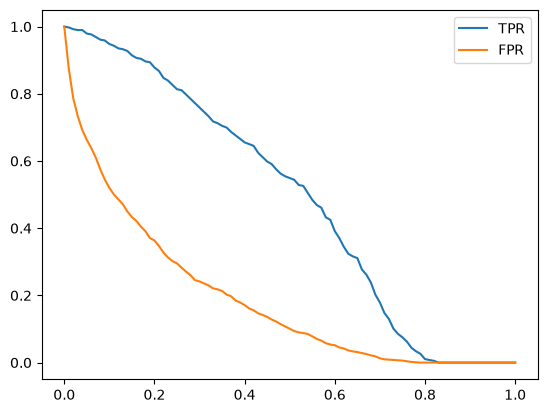

In [77]:
plt.plot(df_scores.threshold, df_scores['tpr'], label = 'TPR')
plt.plot(df_scores.threshold, df_scores['fpr'], label = 'FPR')
plt.legend()

In [78]:
## Random Model

In [79]:
np.random.seed(1)
y_rand = np.random.uniform(0 , 1, size=len(y_val))

In [80]:
y_rand

array([4.17022005e-01, 7.20324493e-01, 1.14374817e-04, ...,
       7.73916250e-01, 3.34276405e-01, 8.89982208e-02], shape=(1409,))

In [81]:
((y_rand >= 0.5)== y_val).mean()

np.float64(0.5017743080198722)

In [82]:
def tpr_fpr_dataframe( y_val , y_pred):
    scores = []

    for t in thresholds:
        actual_positive = (y_val == 1)
        actual_negative = (y_val == 0)
    
        preduct_positive = ( y_pred >= t)
        preduct_negative = ( y_pred < t)
    
        tp = (preduct_positive & actual_positive).sum()
        tn = (preduct_negative & actual_negative).sum()
    
        fp = (preduct_positive & actual_negative).sum()
        fn = (preduct_negative & actual_positive).sum()
    
        scores.append((t,tp , fp , fn , tn))

    columns= ['threshold' , 'tp', 'fp' , 'fn' , 'tn']
    df_scores = pd.DataFrame(scores, columns = columns)

    df_scores['tpr'] = df_scores.tp / ( df_scores.tp + df_scores.fn )
    df_scores['fpr'] = df_scores.fp / ( df_scores.fp + df_scores.tn )

    return df_scores

In [83]:
df_rand =  tpr_fpr_dataframe ( y_val , y_rand)

In [84]:
df_rand[::10]

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,347,923,39,100,0.898964,0.902248
20,0.2,307,822,79,201,0.795337,0.803519
30,0.3,276,724,110,299,0.715026,0.707722
40,0.4,237,624,149,399,0.613990,0.609971
50,0.5,202,518,184,505,0.523316,0.506354
60,0.6,161,409,225,614,0.417098,0.399804
70,0.7,121,302,265,721,0.313472,0.295210
80,0.8,78,206,308,817,0.202073,0.201369
90,0.9,40,101,346,922,0.103627,0.098729


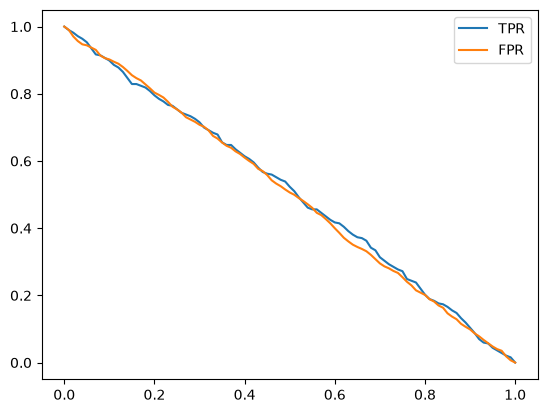

In [85]:
plt.plot(df_rand.threshold, df_rand['tpr'], label = 'TPR')
plt.plot(df_rand.threshold, df_rand['fpr'], label = 'FPR')
plt.legend()

In [86]:
## Ideal Model

In [87]:
num_neg = (  y_val == 0 ).sum()
num_pos = ( y_val ==1 ).sum()
num_neg, num_pos

(np.int64(1023), np.int64(386))

In [88]:
y_ideal = np.repeat([0,1], [num_neg , num_pos])
y_ideal

array([0, 0, 0, ..., 1, 1, 1], shape=(1409,))

In [89]:
y_ideal_pred = np.linspace ( 0, 1, len(y_val))

In [90]:
1 - y_val.mean()

np.float64(0.7260468417317246)

In [91]:
y_ideal_pred

array([0.00000000e+00, 7.10227273e-04, 1.42045455e-03, ...,
       9.98579545e-01, 9.99289773e-01, 1.00000000e+00], shape=(1409,))

In [92]:
((y_ideal_pred >= 0.726) == y_ideal).mean()

np.float64(1.0)

In [93]:
df_ideal =  tpr_fpr_dataframe ( y_ideal , y_ideal_pred)

In [94]:
df_ideal[::10]

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,386,882,0,141,1.000000,0.862170
20,0.2,386,741,0,282,1.000000,0.724340
30,0.3,386,600,0,423,1.000000,0.586510
40,0.4,386,459,0,564,1.000000,0.448680
50,0.5,386,319,0,704,1.000000,0.311828
60,0.6,386,178,0,845,1.000000,0.173998
70,0.7,386,37,0,986,1.000000,0.036168
80,0.8,282,0,104,1023,0.730570,0.000000
90,0.9,141,0,245,1023,0.365285,0.000000


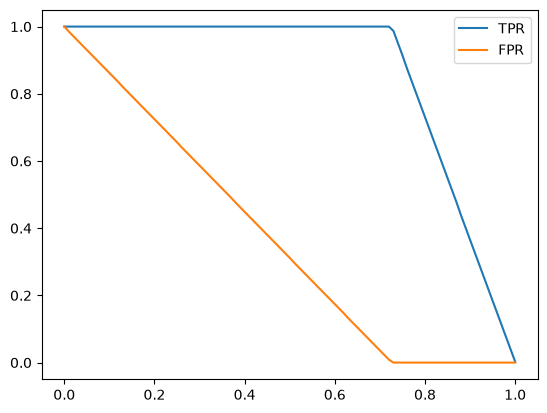

In [95]:
plt.plot(df_ideal.threshold, df_ideal['tpr'], label = 'TPR')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label = 'FPR')
plt.legend()

In [96]:
## Putting everything together

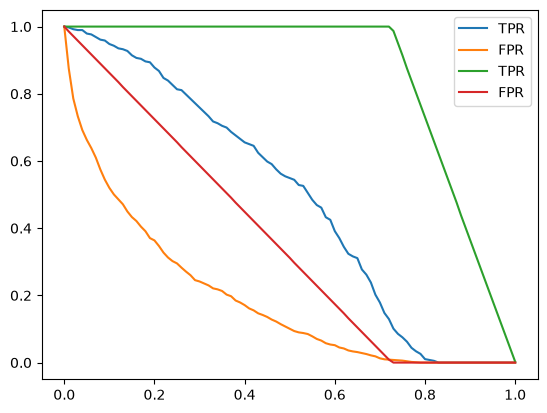

In [97]:
plt.plot(df_scores.threshold, df_scores['tpr'], label = 'TPR')
plt.plot(df_scores.threshold, df_scores['fpr'], label = 'FPR')

#plt.plot(df_rand.threshold, df_rand['tpr'], label = 'TPR')
#plt.plot(df_rand.threshold, df_rand['fpr'], label = 'FPR')

plt.plot(df_ideal.threshold, df_ideal['tpr'], label = 'TPR')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label = 'FPR')

plt.legend()


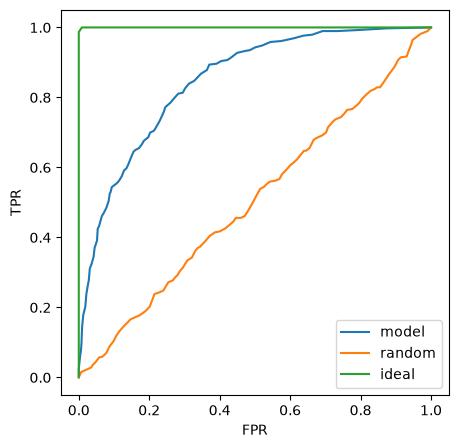

In [98]:
plt.figure(figsize=(5,5))
plt.plot(df_scores.fpr, df_scores.tpr, label='model')
plt.plot(df_rand.fpr, df_rand.tpr, label ='random' )
plt.plot(df_ideal.fpr, df_ideal.tpr, label = 'ideal')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

In [99]:
from sklearn.metrics import roc_curve

In [100]:
fpr , tpr, thresholds = roc_curve(y_val, y_pred)

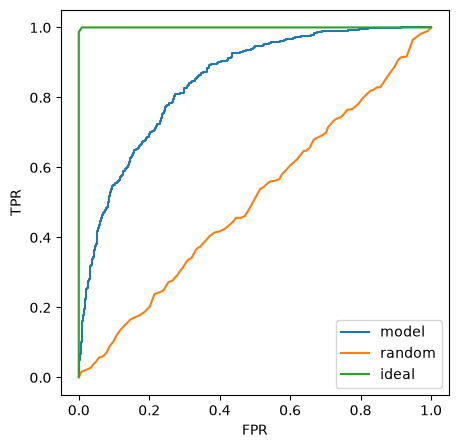

In [101]:
plt.figure(figsize=(5,5))
plt.plot(fpr, tpr, label='model')
plt.plot(df_rand.fpr, df_rand.tpr, label ='random' )
plt.plot(df_ideal.fpr, df_ideal.tpr, label = 'ideal')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

In [102]:
## 4.6 ROC AUC
### Area under the ROC curve - useful metric
### Interpretation of AUC

In [103]:
from sklearn.metrics import auc

In [104]:
auc(fpr , tpr)

0.846286701208981

In [105]:
auc(df_scores.fpr, df_scores.tpr)

0.8460309260075264

In [106]:
auc(df_ideal.fpr, df_ideal.tpr)

0.9999430203759136

In [107]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred)
auc(df_scores.fpr, df_scores.tpr)

0.8460309260075264

In [108]:
from sklearn.metrics import roc_auc_score

In [109]:
roc_auc_score(y_val, y_pred)

0.846286701208981

In [110]:
neg = y_pred[y_val == 0]
pos = y_pred[y_val == 1]

In [111]:
import random

In [112]:
n = 100000
success = 0 

for i in range(n):
    pos_ind = random.randint(9, len(pos) -1)
    neg_ind = random.randint(9, len(neg) -1)
    
    if pos[pos_ind] > neg[neg_ind]:
        success = success + 1

success /n 


0.84811

In [113]:
n= 50000
pos_ind = np.random.randint(0, len(pos), size=n)
neg_ind = np.random.randint(0, len(neg), size=n)

(pos[pos_ind] > neg[neg_ind]).mean()

np.float64(0.84728)

In [114]:
pos[pos_ind]

array([0.17804033, 0.54413169, 0.66161458, ..., 0.39976234, 0.44009251,
       0.15664189], shape=(50000,))

In [115]:
neg_ind

array([ 660,  569,  429, ..., 1018,  434,  792], shape=(50000,))

In [116]:
## 4.7  Cross-Validation
### Evaluating the same model on different subsets of data
### Getting the average prediction and the spread within predictions

In [133]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model= LogisticRegression(C=C , solver='lbfgs' , max_iter=10000)
    model.fit(X_train, y_train)

    return dv, model

In [118]:
dv , model = train(df_train, y_train)

In [119]:
def predict ( df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:,1]

    return y_pred

In [120]:
y_pred = predict(df_val, dv, model)

In [121]:
from sklearn.model_selection import KFold

In [122]:
kfold = KFold(n_splits = 10 , shuffle=True, random_state=1)


In [123]:
next(kfold.split(df_full_train))

(array([   0,    1,    2, ..., 5631, 5632, 5633], shape=(5070,)),
 array([   4,   21,   28,   33,   44,   58,   67,   72,   79,   81,   82,
          98,  101,  116,  119,  125,  126,  136,  141,  147,  161,  169,
         179,  192,  196,  200,  206,  214,  222,  231,  250,  255,  259,
         276,  280,  285,  301,  308,  313,  314,  325,  343,  354,  359,
         383,  386,  407,  420,  428,  433,  440,  447,  457,  473,  486,
         496,  501,  503,  507,  545,  554,  557,  566,  574,  580,  582,
         592,  605,  608,  623,  634,  636,  645,  662,  667,  684,  687,
         689,  729,  745,  758,  763,  778,  783,  792,  795,  808,  839,
         840,  847,  850,  858,  867,  870,  871,  881,  899,  906,  927,
         929,  931,  940,  943,  976,  984,  987,  988, 1005, 1016, 1028,
        1034, 1038, 1050, 1056, 1074, 1079, 1117, 1122, 1123, 1131, 1134,
        1139, 1144, 1155, 1159, 1163, 1169, 1179, 1198, 1206, 1216, 1238,
        1247, 1256, 1272, 1297, 1298, 1310, 13

In [124]:
train_idx , val_idx = next(kfold.split(df_full_train))

In [125]:
len(train_idx) , len(val_idx)

(5070, 564)

In [126]:
len(df_full_train)

5634

In [127]:
df_full_train.iloc[train_idx]

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
1814,5442-pptjy,male,0,yes,yes,12,yes,no,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,19.70,258.35,0
5946,6261-rcvns,female,0,no,no,42,yes,no,dsl,yes,...,yes,yes,no,yes,one_year,no,credit_card_(automatic),73.90,3160.55,1
3881,2176-osjuv,male,0,yes,no,71,yes,yes,dsl,yes,...,no,yes,no,no,two_year,no,bank_transfer_(automatic),65.15,4681.75,0
2389,6161-erdgd,male,0,yes,yes,71,yes,yes,dsl,yes,...,yes,yes,yes,yes,one_year,no,electronic_check,85.45,6300.85,0
611,4765-oxppd,female,0,yes,yes,9,yes,no,dsl,yes,...,yes,yes,no,no,month-to-month,no,mailed_check,65.00,663.05,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2763,2250-ivbwa,male,0,yes,yes,64,yes,no,fiber_optic,yes,...,no,no,no,no,month-to-month,no,electronic_check,81.05,5135.35,0
5192,3507-gasnp,male,0,no,yes,60,yes,no,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,19.95,1189.90,0
3980,8868-wozgu,male,0,no,no,28,yes,yes,fiber_optic,no,...,yes,no,yes,yes,month-to-month,yes,electronic_check,105.70,2979.50,1
235,1251-krreg,male,0,no,no,2,yes,yes,dsl,no,...,no,no,no,no,month-to-month,yes,mailed_check,54.40,114.10,1


In [128]:
!pip install tqdm


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip


In [129]:
from tqdm.auto import tqdm

In [144]:
n_splits = 5

for C in tqdm([ 0.01, 0.001, 0.1, 0.5, 1, 5, 10]):
    kfold = KFold(n_splits = n_splits , shuffle=True, random_state=1)
    
    scores = []
    
    for train_idx , val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
    
        y_train = df_train.churn.values
        y_val = df_val.churn.values
        
        dv, model = train(df_train, y_train,C=C)
        y_pred = predict(df_val, dv, model)
    
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C = %s %.3f +- %.3f' % (C, np.mean(scores) , np.std(scores)))

  0%|          | 0/7 [00:00<?, ?it/s]

C = 0.01 0.840 +- 0.008
C = 0.001 0.825 +- 0.009
C = 0.1 0.842 +- 0.007
C = 0.5 0.842 +- 0.007
C = 1 0.842 +- 0.007
C = 5 0.842 +- 0.007
C = 10 0.842 +- 0.007


In [145]:
dv, model = train(df_full_train, df_full_train.churn.values,C=1.0)
y_pred = predict(df_test, dv, model)

auc = roc_auc_score(y_test, y_pred)
auc


0.8583517501381259

In [146]:
scores

[0.8439175451955006,
 0.8447618692888359,
 0.8333172787477423,
 0.8348048698599475,
 0.8517500235323648]

In [ ]:
## 4.8 Summary
### Metric = A single number that describes the performance of a model
### Accuracy
### 